# Exploratory Data Analysis (EDA)

In [268]:
import os
import random
from pathlib import Path
import matplotlib
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from collections import Counter
from tqdm import tqdm

print(f'Pandas verson: {pd.__version__}')
print(f'Matplotlib verson: {matplotlib.__version__}')
print(f'Pillow version: {Image.__version__}')

my_random = 2441156

# the following excluded images were found during the dataset 
# inspectionto be non relevant to the rest of the dataset
excluded_images = {
    Path("../../../../Datasets/PlantVillage-Dataset/raw/color/Pepper,_bell___healthy/42f083e2-272d-4f83-ad9a-573ee90e50ec___Screen Shot 2015-05-06 at 4.01.13 PM.png")
}

Pandas verson: 3.1.0
Matplotlib verson: 3.11.2
Pillow version: 13.0.0


#### List directories

In [240]:
images_path = Path('../../../../Datasets/PlantVillage-Dataset/raw/color')

classes = [x.name for x in images_path.iterdir() if x.is_dir() ]
number_classes = len(classes)

print(f'Directories - classes: {classes}')
print(f'Total directories - classes: {len(classes)}')

Directories - classes: ['Apple___Apple_scab', 'Apple___Black_rot', 'Apple___Cedar_apple_rust', 'Apple___healthy', 'Blueberry___healthy', 'Cherry_(including_sour)___healthy', 'Cherry_(including_sour)___Powdery_mildew', 'Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot', 'Corn_(maize)___Common_rust_', 'Corn_(maize)___healthy', 'Corn_(maize)___Northern_Leaf_Blight', 'Grape___Black_rot', 'Grape___Esca_(Black_Measles)', 'Grape___healthy', 'Grape___Leaf_blight_(Isariopsis_Leaf_Spot)', 'Orange___Haunglongbing_(Citrus_greening)', 'Peach___Bacterial_spot', 'Peach___healthy', 'Pepper,_bell___Bacterial_spot', 'Pepper,_bell___healthy', 'Potato___Early_blight', 'Potato___healthy', 'Potato___Late_blight', 'Raspberry___healthy', 'Soybean___healthy', 'Squash___Powdery_mildew', 'Strawberry___healthy', 'Strawberry___Leaf_scorch', 'Tomato___Bacterial_spot', 'Tomato___Early_blight', 'Tomato___healthy', 'Tomato___Late_blight', 'Tomato___Leaf_Mold', 'Tomato___Septoria_leaf_spot', 'Tomato___Spider_mites Tw

#### Count number of images per class

In [259]:
valid_extensions = {'.jpg', '.jpeg', '.png'}
class_counts = []
class_distribution = {}
all_images = []

for x in classes:
    class_dir = images_path / x
    
    class_images = [ i for i in class_dir.iterdir() if i.is_file() and i.suffix.lower() in valid_extensions ]

    class_counts.append(len(class_images))
    class_distribution[x] = len(class_images)
    all_images.extend(class_images)

    # print(f'{x}: {len(number_images)}' )

class_counts.sort()
class_distribution = dict(sorted(class_distribution.items(), key = lambda item: item[1]))


print(f'\nClass counts sorted L-H: {class_counts}')
print(f'\nClass name + count sorted L-H: {class_distribution}')
print(f'\nTotal images: {sum(class_counts)}')
# print(f'Total images: {len(all_images)}')
print(f'Smallest class: {min(class_counts)}')
print(f'Largest class: {max(class_counts)}')


Class counts sorted L-H: [152, 275, 360, 371, 373, 423, 456, 513, 621, 630, 854, 952, 985, 997, 1000, 1000, 1000, 1052, 1076, 1109, 1162, 1180, 1192, 1383, 1404, 1478, 1502, 1591, 1645, 1676, 1771, 1835, 1909, 2127, 2297, 5090, 5357, 5507]

Class name + count sorted L-H: {'Potato___healthy': 152, 'Apple___Cedar_apple_rust': 275, 'Peach___healthy': 360, 'Raspberry___healthy': 371, 'Tomato___Tomato_mosaic_virus': 373, 'Grape___healthy': 423, 'Strawberry___healthy': 456, 'Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot': 513, 'Apple___Black_rot': 621, 'Apple___Apple_scab': 630, 'Cherry_(including_sour)___healthy': 854, 'Tomato___Leaf_Mold': 952, 'Corn_(maize)___Northern_Leaf_Blight': 985, 'Pepper,_bell___Bacterial_spot': 997, 'Potato___Early_blight': 1000, 'Potato___Late_blight': 1000, 'Tomato___Early_blight': 1000, 'Cherry_(including_sour)___Powdery_mildew': 1052, 'Grape___Leaf_blight_(Isariopsis_Leaf_Spot)': 1076, 'Strawberry___Leaf_scorch': 1109, 'Corn_(maize)___healthy': 1162, 'Gr

#### Represent the image distribution on a graph

Text(0, 0.5, 'Class')

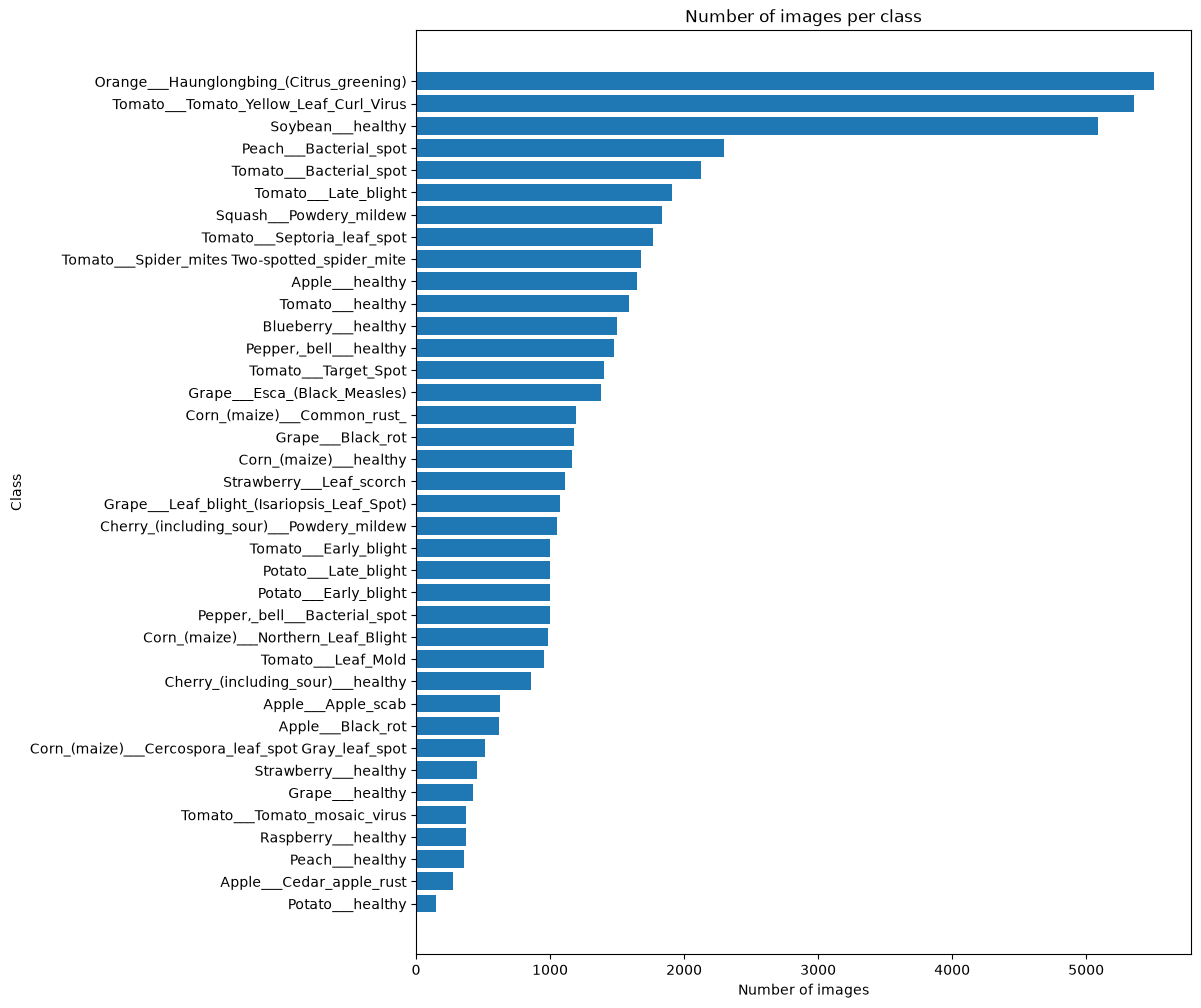

In [242]:
plt.figure(figsize=(10, 12))

plt.barh(y=class_distribution.keys(), width=class_distribution.values())

plt.title('Number of images per class')
plt.xlabel('Number of images')
plt.ylabel('Class')

# plt.tight_layout()

#### Inspect images properties

##### One sample

Image size: (256, 256)
Image mode: RGB
Image format: JPEG


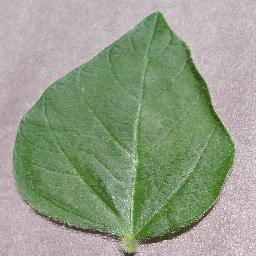

In [ ]:
random.seed(my_random)

img = Image.open(random.choice(all_images))

print(f'Image size: {img.size}')
print(f'Image mode: {img.mode}')
print(f'Image format: {img.format}')

display(img)

##### Check size consistency across all images

In [247]:
images_sizes = []
images_channels = []
images_formats = []

for image in tqdm(all_images):
    with Image.open(image) as img:
        images_sizes.append(img.size)
        images_channels.append(img.mode)
        images_formats.append(img.format)

print(f'Image size distribution: {Counter(images_sizes)}')
print(f'Image channel mode distribution: {Counter(images_channels)}')
print(f'Image format distribution: {Counter(images_formats)}')

100%|██████████| 54305/54305 [00:06<00:00, 7834.36it/s]

Image size distribution: Counter({(256, 256): 54305})
Image channel mode distribution: Counter({'RGB': 54304, 'RGBA': 1})
Image format distribution: Counter({'JPEG': 54304, 'PNG': 1})


##### Display the unusual PNG image

 43%|████▎     | 23495/54305 [00:02<00:03, 7730.91it/s]

PNG image: ..\..\..\..\Datasets\PlantVillage-Dataset\raw\color\Pepper,_bell___healthy\42f083e2-272d-4f83-ad9a-573ee90e50ec___Screen Shot 2015-05-06 at 4.01.13 PM.png


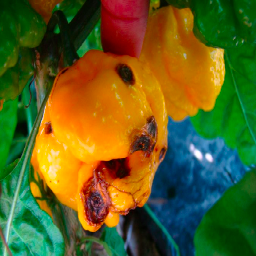

100%|██████████| 54305/54305 [00:06<00:00, 8048.55it/s]


In [254]:
for image in tqdm(all_images):
    with Image.open(image) as img:
            if img.mode != "RGB":
                  print(f'PNG image: {image}')
                  display(img)
                  

##### Image appears to be a diseased fruit not leaf. 
Exclude it from the target dataset and double check.

In [276]:
clean_images = [
    image for image in all_images
    if image not in excluded_images
]

all_rgb = True

for image in tqdm(clean_images):
    with Image.open(image) as img:
        if img.mode != "RGB" or img.format != "JPEG":
            all_rgb = False

print(f'Number of images: {len(clean_images)} - {'All RGB' if all_rgb else 'Not all RGB!'}')

100%|██████████| 54304/54304 [00:11<00:00, 4750.27it/s]

Number of images: 54304 - All RGB


### Display few sample images

In [ ]:
random.seed(my_random)

images_to_show = []

for x in classes:
    class_dir = images_path / x
    class_images = [ i for i in class_dir.iterdir() if i.is_file() and i.suffix.lower() in valid_extensions ]

    images_to_show.append(random.choice(class_images))

random.shuffle(images_to_show)
selected_images = images_to_show[:9]
print(f'Number of images to show: {len(selected_images)}')

Number of images to show: 9


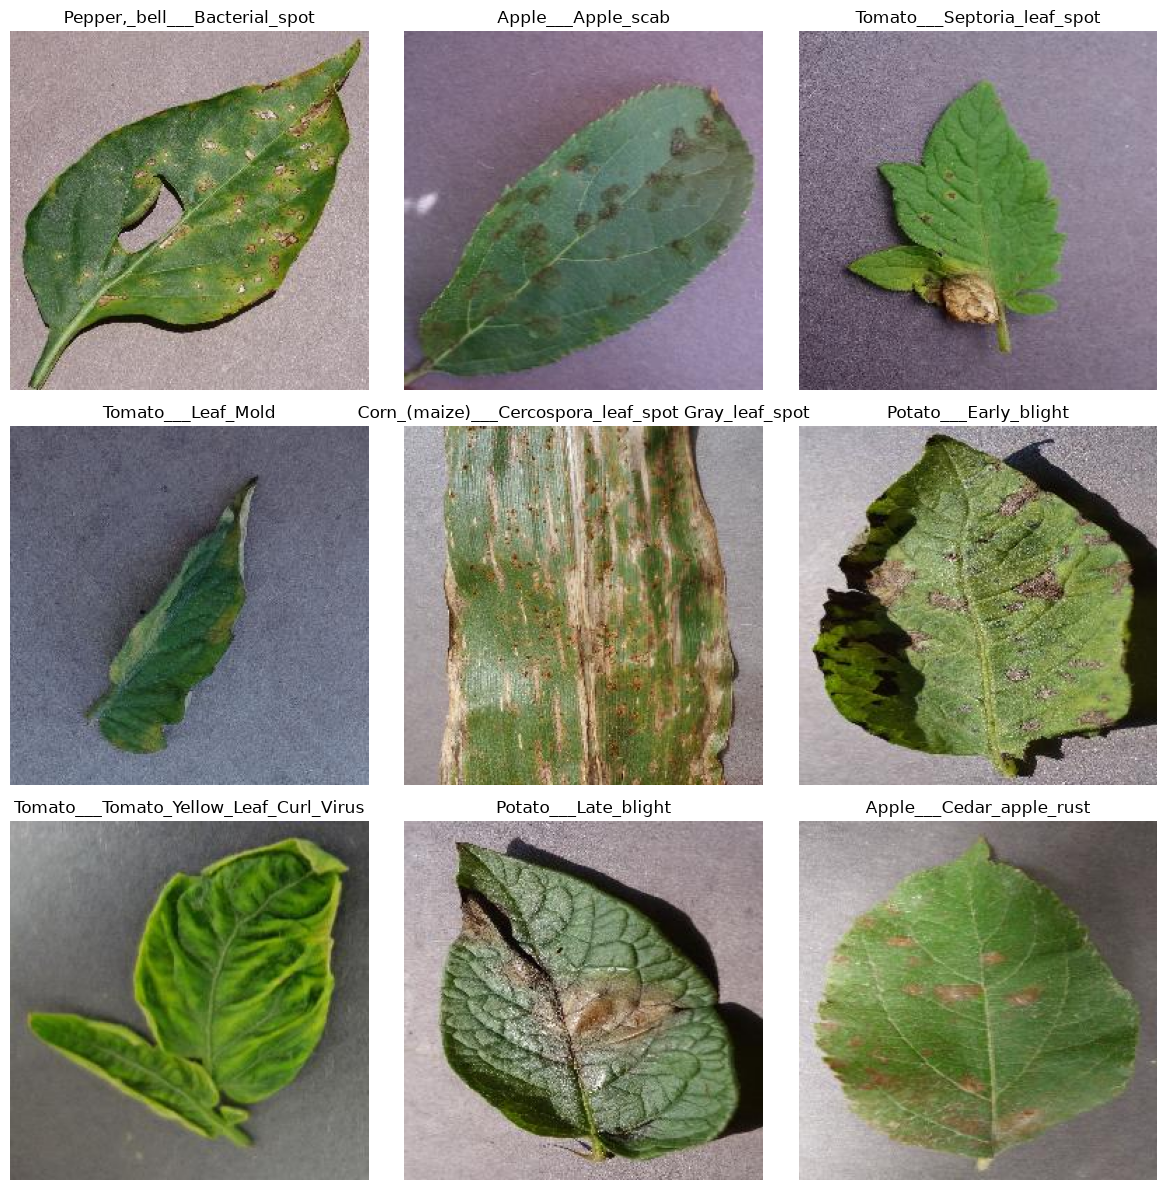

In [333]:
random.seed(my_random)

plt.figure(figsize=(12, 12))

for i in range(len(selected_images)):
    image_path = selected_images[i]
    image = Image.open(image_path)

    class_name = image_path.parent.name
    
    plt.subplot(3, 3, i + 1)
    plt.imshow(image)
    plt.title(class_name)
    plt.axis("off")

plt.tight_layout()
plt.show()